In [16]:
import pandas as pd

nasa = pd.read_csv("PSCompPars.csv", sep=None, engine="python")
phl = pd.read_csv("HWC_exoplanet.csv", sep=None, engine="python")

print("NASA data:")
print(nasa.head())

print("\nPHL data:")
print(phl.head())

NASA data:
      pl_name  discoverymethod  disc_year  \
0    11 Com b  Radial Velocity       2007   
1    11 UMi b  Radial Velocity       2009   
2    14 And b  Radial Velocity       2008   
3    14 Her b  Radial Velocity       2002   
4  16 Cyg B b  Radial Velocity       1996   

                            disc_facility  pl_rade  pl_radeerr1  pl_radeerr2  \
0                        Xinglong Station     12.2          NaN          NaN   
1  Thueringer Landessternwarte Tautenburg     12.3          NaN          NaN   
2       Okayama Astrophysical Observatory     13.1          NaN          NaN   
3                  W. M. Keck Observatory     12.6          NaN          NaN   
4                  Multiple Observatories     13.5          NaN          NaN   

   pl_radelim    pl_bmasse  pl_bmasseerr1  ...  st_raderr1  st_raderr2  \
0         0.0  4914.898486      39.092894  ...        2.85       -2.45   
1         0.0  4684.814200     794.575000  ...        2.84       -2.84   
2         0.0  

In [8]:

nasa_clean = nasa.rename(columns={
    "pl_name": "Planet Name",
    "pl_bmasse": "Mass (Earth Masses)",
    "pl_rade": "Radius (Earth Radii)",
    "sy_dist": "Distance (pc)",
    "disc_year": "Discovery Year",
    "discoverymethod": "Discovery Method"
})

 
phl_clean = phl.rename(columns={
    "Name": "Planet Name",
    "Detection Method": "Discovery Method",
    "Mass<br>(M<sub>E</sub>)": "Mass (Earth Masses)",
    "Radius<br>(R<sub>E</sub>)": "Radius (Earth Radii)",
    "Flux<br>(S<sub>E</sub>)": "Flux (Earth=1)",
    "<i>T<sub>surf</sub></i><br>(K)": "Surface Temperature (K)",
    "Period<br>(days)": "Orbital Period (days)",
    "Distance<br>(ly)": "Distance (ly)",
    "Age<br>(Gy)": "Age (Gy)"
})

print(" Cleaned NASA Columns:")
print(nasa_clean.columns[:10])
print("\n Cleaned PHL Columns:")
print(phl_clean.columns[:10])

 Cleaned NASA Columns:
Index(['Planet Name', 'Discovery Method', 'Discovery Year', 'disc_facility',
       'Radius (Earth Radii)', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim',
       'Mass (Earth Masses)', 'pl_bmasseerr1'],
      dtype='object')

 Cleaned PHL Columns:
Index(['Planet Name', 'Type', 'Discovery Method', 'Mass (Earth Masses)',
       'Radius (Earth Radii)', 'Flux (Earth=1)', 'Surface Temperature (K)',
       'Orbital Period (days)', 'Distance (ly)', 'Age (Gy)'],
      dtype='object')


In [9]:

nasa_final = nasa_clean[[
    "Planet Name", "Discovery Method", "Discovery Year",
    "Mass (Earth Masses)", "Radius (Earth Radii)", "Distance (pc)"
]].dropna(subset=["Mass (Earth Masses)", "Radius (Earth Radii)"])


phl_clean["Distance (pc)"] = phl_clean["Distance (ly)"] * 0.306601  # 1 ly = 0.306601 pc

phl_final = phl_clean[[
    "Planet Name", "Type", "Discovery Method",
    "Mass (Earth Masses)", "Radius (Earth Radii)",
    "Distance (pc)", "Surface Temperature (K)",
    "Flux (Earth=1)", "Orbital Period (days)", "Age (Gy)"
]].dropna(subset=["Mass (Earth Masses)", "Radius (Earth Radii)"])

print(" NASA Final Shape:", nasa_final.shape)
print(" PHL Final Shape:", phl_final.shape)

 NASA Final Shape: (5994, 6)
 PHL Final Shape: (70, 10)


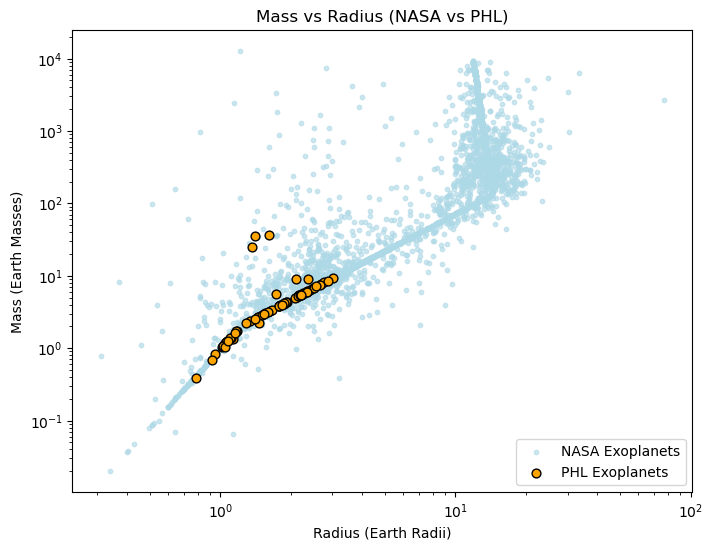

In [13]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8,6))
plt.scatter(nasa_final["Radius (Earth Radii)"], nasa_final["Mass (Earth Masses)"],
            color='lightblue', s=10, label="NASA Exoplanets", alpha=0.6)
plt.scatter(phl_final["Radius (Earth Radii)"], phl_final["Mass (Earth Masses)"],
            color='orange', s=40, label="PHL Exoplanets", edgecolors='k')
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Radius (Earth Radii)")
plt.ylabel("Mass (Earth Masses)")
plt.title("Mass vs Radius (NASA vs PHL)")
plt.legend()
plt.show()


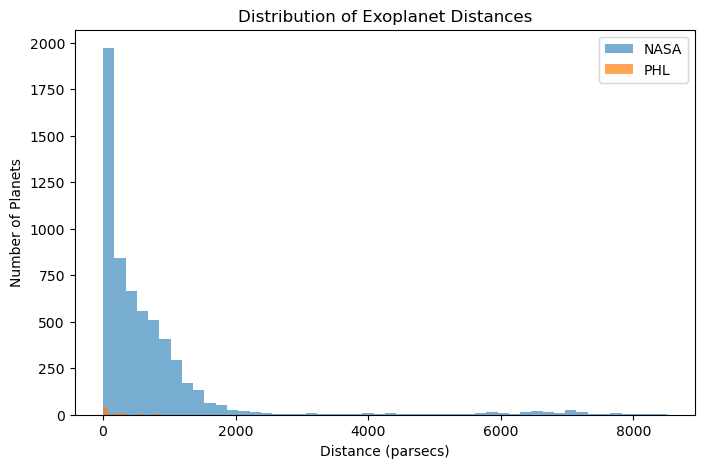

In [11]:
#  Distance distribution comparison
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(nasa_final["Distance (pc)"], bins=50, alpha=0.6, label="NASA")
plt.hist(phl_final["Distance (pc)"], bins=20, alpha=0.7, label="PHL")
plt.xlabel("Distance (parsecs)")
plt.ylabel("Number of Planets")
plt.title("Distribution of Exoplanet Distances")
plt.legend()
plt.show()

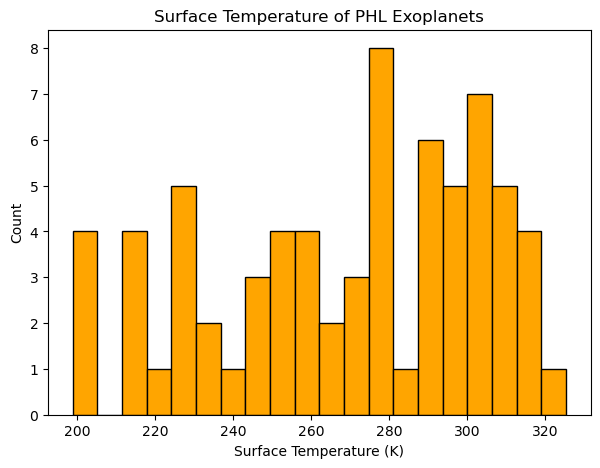

In [12]:
# Surface Temperature (PHL only)
plt.figure(figsize=(7,5))
plt.hist(phl_final["Surface Temperature (K)"], bins=20, color="orange", edgecolor="black")
plt.xlabel("Surface Temperature (K)")
plt.ylabel("Count")
plt.title("Surface Temperature of PHL Exoplanets")
plt.show()

In [6]:
print("=== NASA Summary ===")
print(nasa_final[["Mass (Earth Masses)", "Radius (Earth Radii)", "Distance (pc)"]].describe())

print("\n=== PHL Summary ===")
print(phl_final[["Mass (Earth Masses)", "Radius (Earth Radii)", "Distance (pc)", "Surface Temperature (K)"]].describe())

=== NASA Summary ===
       Mass (Earth Masses)  Radius (Earth Radii)  Distance (pc)
count          5994.000000           5994.000000    5969.000000
mean            386.092363              5.772696     701.643022
std            1109.840300              5.315066    1178.212039
min               0.020000              0.309800       1.301190
25%               4.120000              1.820000     103.917000
50%               9.030000              2.820000     384.694000
75%             179.017074             11.900000     833.165000
max           12651.500000             77.342100    8500.000000

=== PHL Summary ===
       Mass (Earth Masses)  Radius (Earth Radii)  Distance (pc)  \
count            70.000000             70.000000      70.000000   
mean              5.288748              1.770514     156.755089   
std               6.247585              0.557559     261.424917   
min               0.388000              0.788000       1.301187   
25%               2.202500              1.30250

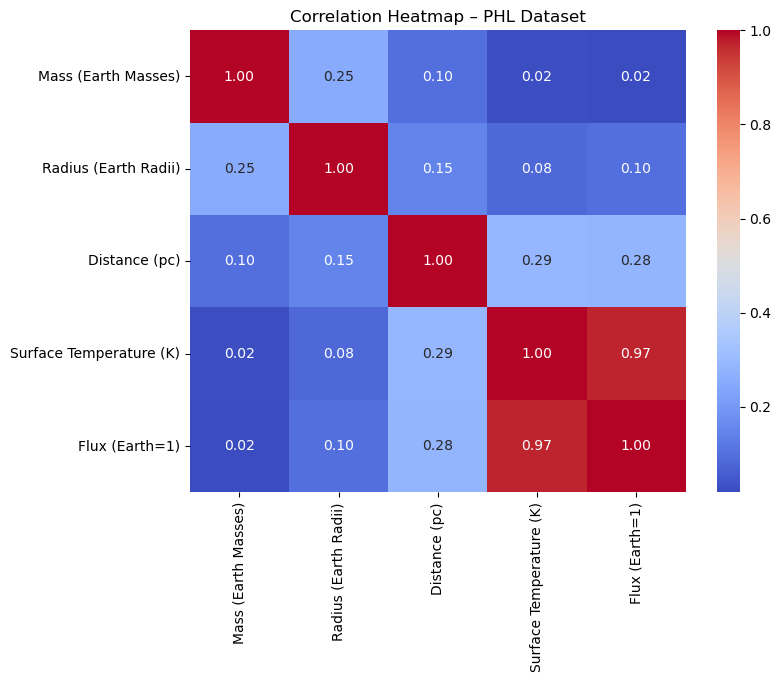

In [14]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(
    phl_final[[
        "Mass (Earth Masses)", 
        "Radius (Earth Radii)", 
        "Distance (pc)",
        "Surface Temperature (K)", 
        "Flux (Earth=1)"
    ]].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Heatmap – PHL Dataset")
plt.show()

In [8]:
#Habitability filtering

habitable = phl_final[
    (phl_final["Surface Temperature (K)"] >= 240) &
    (phl_final["Surface Temperature (K)"] <= 320) &
    (phl_final["Radius (Earth Radii)"] >= 0.5) &
    (phl_final["Radius (Earth Radii)"] <= 2.5) &
    (phl_final["Mass (Earth Masses)"] >= 0.1) &
    (phl_final["Mass (Earth Masses)"] <= 10)
]

print("Number of potentially habitable planets:", habitable.shape[0])
habitable.head()

Number of potentially habitable planets: 47


,Planet Name,Type,Discovery Method,Mass (Earth Masses),Radius (Earth Radii),Distance (pc),Surface Temperature (K),Flux (Earth=1),Orbital Period (days),Age (Gy)
0,TOI-904 c,M Warm Superterran,Transit,5.340,2.167,46.088987,244.820750,0.524434,83.99970,1.5
1,TOI-700 e,M Warm Terran,Transit,0.818,0.953,31.126424,305.688111,1.278049,27.80978,1.5
2,TOI-700 d,M Warm Terran,Transit,1.250,1.073,31.126424,276.939259,0.859827,37.42396,1.5
5,GJ 180 c,M Warm Superterran,Radial Velocity,6.400,2.410,11.940671,270.340012,0.784489,24.32900,NaN
6,GJ 433 d,M Warm Superterran,Radial Velocity,5.223,2.140,9.064538,291.630098,1.059807,36.05900,NaN


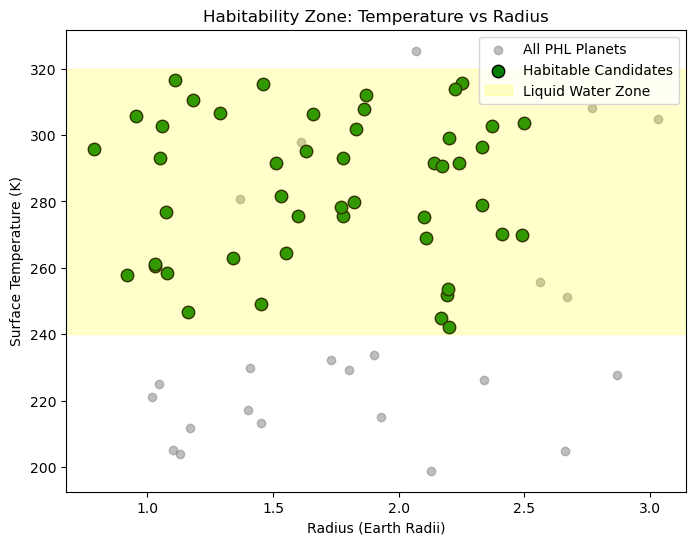

In [9]:
plt.figure(figsize=(8,6))
plt.scatter(phl_final["Radius (Earth Radii)"], phl_final["Surface Temperature (K)"],
            color="grey", alpha=0.5, label="All PHL Planets")

plt.scatter(habitable["Radius (Earth Radii)"], habitable["Surface Temperature (K)"],
            color="green", edgecolors="black", s=80, label="Habitable Candidates")

plt.axhspan(240, 320, color='yellow', alpha=0.2, label="Liquid Water Zone")
plt.xlabel("Radius (Earth Radii)")
plt.ylabel("Surface Temperature (K)")
plt.title("Habitability Zone: Temperature vs Radius")
plt.legend()
plt.show()

In [10]:
summary = habitable[[
    "Planet Name", 
    "Type",
    "Mass (Earth Masses)",
    "Radius (Earth Radii)",
    "Surface Temperature (K)",
    "Flux (Earth=1)",
    "Distance (pc)"
]]

summary.sort_values(by="Surface Temperature (K)").head(15)

,Planet Name,Type,Mass (Earth Masses),Radius (Earth Radii),Surface Temperature (K),Flux (Earth=1),Distance (pc)
54,HN Lib b,M Warm Superterran,5.460,2.200,242.281867,0.505382,6.244405
0,TOI-904 c,M Warm Superterran,5.340,2.167,244.820750,0.524434,46.088987
63,GJ 1061 d,M Warm Terran,1.640,1.160,246.575633,0.686780,3.672771
32,GJ 667 C f,M Warm Terran,2.700,1.450,249.223383,0.563568,7.243942
44,Kepler-174 d,K Warm Superterran,5.430,2.190,251.843755,0.587250,384.756060
48,TOI-2257 b,M Warm Superterran,5.450,2.194,253.700717,0.744017,57.790959
33,TRAPPIST-1 e,M Warm Terran,0.692,0.920,257.995351,0.646776,12.429858
69,Wolf 1069 b,M Warm Terran,1.260,1.080,258.518058,0.652021,9.583387
27,GJ 1002 b,M Warm Terran,1.080,1.030,260.595805,0.673236,4.848658
42,Proxima Cen b,M Warm Terran,1.070,1.030,261.081034,0.678468,1.301187


In [12]:
#Compute Earth Similarity Index (ESI)

import numpy as np

# Avoid division issues
phl_final = phl_final.copy()

# ESI Radius
phl_final["ESI_Radius"] = 1 - abs((phl_final["Radius (Earth Radii)"] - 1) / 
                                 (phl_final["Radius (Earth Radii)"] + 1))

# ESI Temperature
phl_final["ESI_Temp"] = 1 - abs((phl_final["Surface Temperature (K)"] - 288) / 
                               (phl_final["Surface Temperature (K)"] + 288))

# Combined ESI
phl_final["ESI"] = np.sqrt(phl_final["ESI_Radius"] * phl_final["ESI_Temp"])

# Show top Earth-like planets
esi_sorted = phl_final.sort_values(by="ESI", ascending=False)
esi_sorted.head(10)

,Planet Name,Type,Discovery Method,Mass (Earth Masses),Radius (Earth Radii),Distance (pc),Surface Temperature (K),Flux (Earth=1),Orbital Period (days),Age (Gy),ESI_Radius,ESI_Temp,ESI
9,Teegarden's Star b,M Warm Terran,Radial Velocity,1.160,1.050,3.830771,293.090137,1.077943,4.906340,8.0,0.975610,0.991240,0.983394
1,TOI-700 e,M Warm Terran,Transit,0.818,0.953,31.126424,305.688111,1.278049,27.809780,1.5,0.975934,0.970206,0.973066
13,Kepler-1649 c,M Warm Terran,Transit,1.200,1.060,92.191075,302.728405,1.226057,19.535270,NaN,0.970874,0.975067,0.972968
2,TOI-700 d,M Warm Terran,Transit,1.250,1.073,31.126424,276.939259,0.859827,37.423960,1.5,0.964785,0.980421,0.972572
42,Proxima Cen b,M Warm Terran,Radial Velocity,1.070,1.030,1.301187,261.081034,0.678468,11.186800,NaN,0.985222,0.950975,0.967947
27,GJ 1002 b,M Warm Terran,Radial Velocity,1.080,1.030,4.848658,260.595805,0.673236,10.346500,NaN,0.985222,0.950047,0.967474
69,Wolf 1069 b,M Warm Terran,Radial Velocity,1.260,1.080,9.583387,258.518058,0.652021,15.564000,NaN,0.961538,0.946055,0.953765
33,TRAPPIST-1 e,M Warm Terran,Transit,0.692,0.920,12.429858,257.995351,0.646776,6.101013,0.5,0.958333,0.945046,0.951666
47,Ross 128 b,M Warm Terran,Radial Velocity,1.400,1.110,3.374532,316.641714,1.482444,9.865800,5.0,0.947867,0.952630,0.950246
53,GJ 1061 c,M Warm Terran,Radial Velocity,1.740,1.180,3.672771,310.495804,1.448571,6.689000,7.0,0.917431,0.962413,0.939653


In [13]:
#Merge NASA and PHL datasets on planet name
merged_planets = pd.merge(nasa_final, phl_final, on="Planet Name", how="inner")

print("Number of planets appearing in both NASA & PHL:", merged_planets.shape[0])
merged_planets.head(10)

Number of planets appearing in both NASA & PHL: 70


,Planet Name,Discovery Method_x,Discovery Year,Mass (Earth Masses)_x,Radius (Earth Radii)_x,Distance (pc)_x,Type,Discovery Method_y,Mass (Earth Masses)_y,Radius (Earth Radii)_y,Distance (pc)_y,Surface Temperature (K),Flux (Earth=1),Orbital Period (days),Age (Gy),ESI_Radius,ESI_Temp,ESI
0,GJ 1002 b,Radial Velocity,2022,1.080000,1.03,4.848670,M Warm Terran,Radial Velocity,1.08000,1.03,4.848658,260.595805,0.673236,10.34650,NaN,0.985222,0.950047,0.967474
1,GJ 1002 c,Radial Velocity,2022,1.360000,1.10,4.848670,M Warm Terran,Radial Velocity,1.36000,1.10,4.848658,205.067738,0.258159,21.20200,NaN,0.952381,0.831804,0.890053
2,GJ 1061 c,Radial Velocity,2020,1.740000,1.18,3.672780,M Warm Terran,Radial Velocity,1.74000,1.18,3.672771,310.495804,1.448571,6.68900,7.0,0.917431,0.962413,0.939653
3,GJ 1061 d,Radial Velocity,2020,1.640000,1.16,3.672780,M Warm Terran,Radial Velocity,1.64000,1.16,3.672771,246.575633,0.686780,13.03100,7.0,0.925926,0.922510,0.924216
4,GJ 163 c,Radial Velocity,2013,6.800000,2.50,15.128500,M Warm Superterran,Radial Velocity,6.80000,2.50,15.128463,303.745620,1.251825,25.63058,6.0,0.571429,0.973391,0.745804
5,GJ 180 c,Radial Velocity,2014,6.400000,2.41,11.940700,M Warm Superterran,Radial Velocity,6.40000,2.41,11.940671,270.340012,0.784489,24.32900,NaN,0.586510,0.968371,0.753631
6,GJ 180 d,Radial Velocity,2020,7.560000,2.66,11.940700,M Warm Superterran,Radial Velocity,7.56000,2.66,11.940671,204.720567,0.260244,106.30000,NaN,0.546448,0.830980,0.673860
7,GJ 229 A c,Radial Velocity,2020,8.581367,2.87,5.756240,M Warm Superterran,Radial Velocity,8.58137,2.87,5.756226,227.764557,0.437087,121.93268,0.4,0.516796,0.883211,0.675603
8,GJ 273 b,Radial Velocity,2017,2.890000,1.51,5.921535,M Warm Terran,Radial Velocity,2.89000,1.51,3.786051,291.670019,1.064477,18.64980,NaN,0.796813,0.993669,0.889813
9,GJ 3293 d,Radial Velocity,2017,7.600000,2.67,20.190300,M Warm Superterran,Radial Velocity,7.60000,2.67,20.190251,251.304031,0.588593,48.13450,NaN,0.544959,0.931957,0.712656


In [14]:
#Final summary table for report

final_summary = esi_sorted[[
    "Planet Name",
    "Type",
    "Mass (Earth Masses)",
    "Radius (Earth Radii)",
    "Surface Temperature (K)",
    "Distance (pc)",
    "Flux (Earth=1)",
    "Orbital Period (days)",
    "ESI"
]]

#top 15 most Earth-like planets
final_summary.head(15)

,Planet Name,Type,Mass (Earth Masses),Radius (Earth Radii),Surface Temperature (K),Distance (pc),Flux (Earth=1),Orbital Period (days),ESI
9,Teegarden's Star b,M Warm Terran,1.160,1.050,293.090137,3.830771,1.077943,4.906340,0.983394
1,TOI-700 e,M Warm Terran,0.818,0.953,305.688111,31.126424,1.278049,27.809780,0.973066
13,Kepler-1649 c,M Warm Terran,1.200,1.060,302.728405,92.191075,1.226057,19.535270,0.972968
2,TOI-700 d,M Warm Terran,1.250,1.073,276.939259,31.126424,0.859827,37.423960,0.972572
42,Proxima Cen b,M Warm Terran,1.070,1.030,261.081034,1.301187,0.678468,11.186800,0.967947
27,GJ 1002 b,M Warm Terran,1.080,1.030,260.595805,4.848658,0.673236,10.346500,0.967474
69,Wolf 1069 b,M Warm Terran,1.260,1.080,258.518058,9.583387,0.652021,15.564000,0.953765
33,TRAPPIST-1 e,M Warm Terran,0.692,0.920,257.995351,12.429858,0.646776,6.101013,0.951666
47,Ross 128 b,M Warm Terran,1.400,1.110,316.641714,3.374532,1.482444,9.865800,0.950246
53,GJ 1061 c,M Warm Terran,1.740,1.180,310.495804,3.672771,1.448571,6.689000,0.939653
